In [1]:
from plotnine import *

In [31]:
import pandas as pd
cc = pd.read_csv('../CellCycleCounts/CellCycleCounts-subreg/ccCountHashSubReg.csv')
cc

,Var1,Var2,Var3,Freq
0,G1,0,Hash1,388
1,G2M,0,Hash1,60
2,S,0,Hash1,106
3,G1,1,Hash1,1
4,G2M,1,Hash1,244
...,...,...,...,...
67,G2M,4,Hash5,4
68,S,4,Hash5,11
69,G1,5,Hash5,34
70,G2M,5,Hash5,15


In [42]:
cc.columns = ['Phase','Subset','Sample','Freq']
cc['Subset'] = cc.Subset.replace({0:'cDC', 1:'HSPC1', 2:'HSPC2', 3:'pDC', 4:'Neutro', 5: 'cd8DC'})

## stupid code
#cc['Var3'] = cc.Var3.replace({'Hash1':'1 WTd3', 'Hash2':'2 KOd3', 'Hash3':'3 WTd5', 'Hash5':'4 KOd5'})
#cc['Var1'] = cc.Var1.replace(['S','G1','G2M'],['2 S','3 G1','1 G2M'])

cc['Sample'] = cc.Sample.replace({'Hash1':'WTd3', 'Hash2':'KOd3', 'Hash3':'WTd5', 'Hash5':'KOd5'})
cc['Phase'] = cc.Phase.replace(['S','G1','G2M'],['2','3','1'])

In [33]:
## tried to pivot and collapse
#cc2 = pd.pivot_table(cc, index=['Var2','Var3'], columns='Var1', values=['Freq']).reset_index()
#cc2.columns = ['Subset','Hash','G1','G2M','S'] #cc2.columns.get_level_values(0)
#cc2

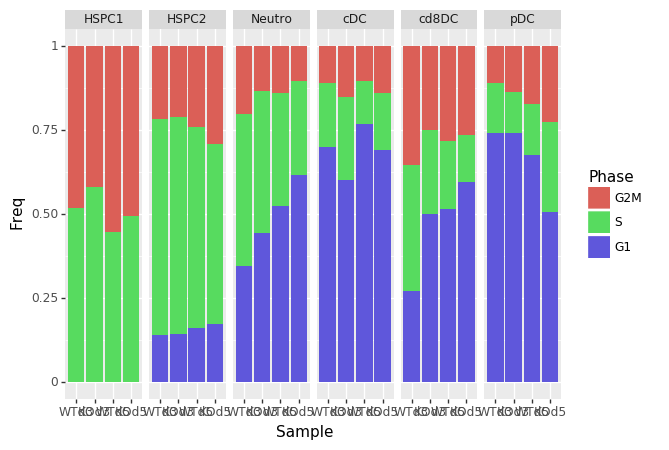

<ggplot: (8767729818001)>

In [64]:
p = (ggplot(cc, aes(x='Sample', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('~Subset')
 + scale_x_discrete(name ='Sample', 
                    limits=['WTd3','KOd3','WTd5','KOd5'])
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p

In [83]:
#p.save(filename='ccScore.png', dpi=300)
p.save(filename='ccScore-1line.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-1line.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


In [73]:
## use map to replace string according to dict{}
#day = {'WTd3':'3','KOd3':'3','WTd5':'5','KOd5':'5'}
#cc['Sample'].map(day)
#geno = {'WTd3':'WT','KOd3':'WT','WTd5':'KO','KOd5':'KO'}
#cc['Sample'].map(geno)

## slice WTd3 to get geno and day
cc['Geno'] = cc['Sample'].str.slice(0,2)
cc['Day'] = cc['Sample'].str.slice(3,)

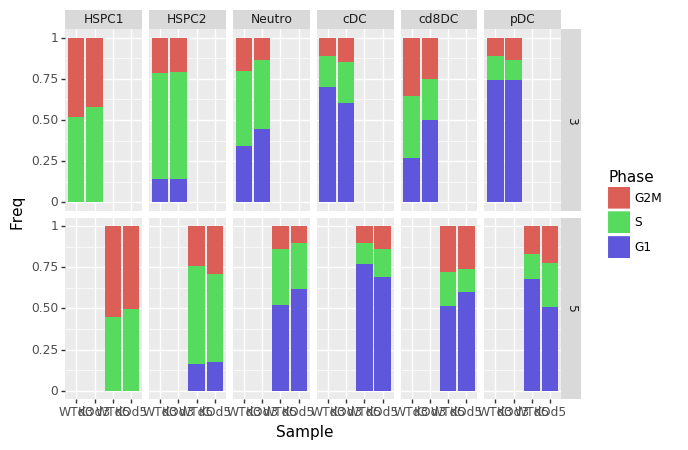

<ggplot: (8767729684257)>

In [81]:
p1 = (ggplot(cc, aes(x='Sample', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Sample', 
                     limits=['WTd3','KOd3','WTd5','KOd5']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p1

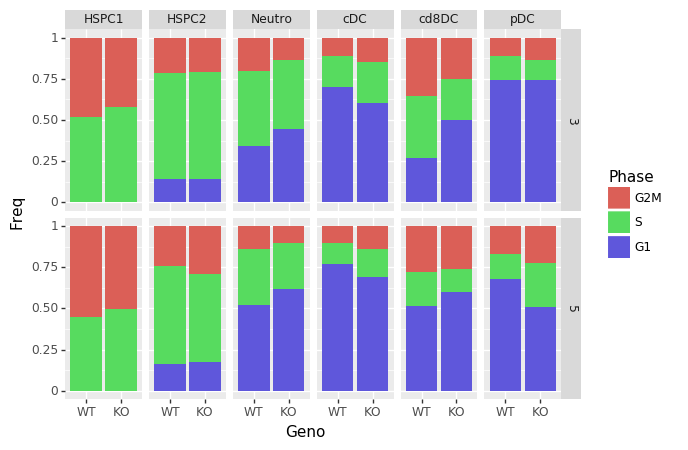

<ggplot: (8767728364297)>

In [82]:
p2 = (ggplot(cc, aes(x='Geno', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Geno', 
                     limits=['WT','KO']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p2

In [84]:
p2.save(filename='ccScore-geno~day.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-geno~day.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


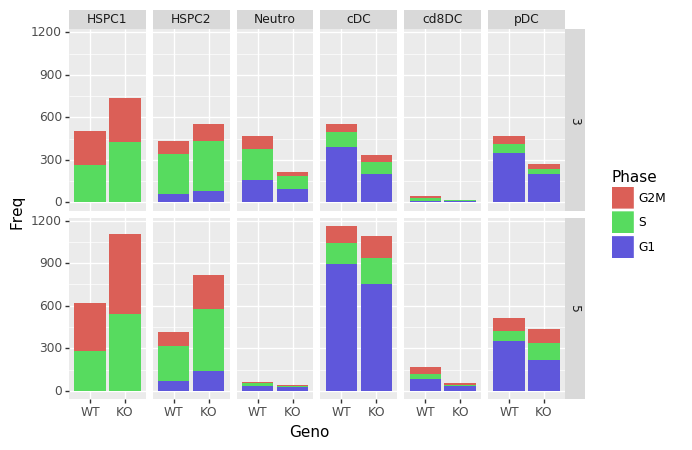

<ggplot: (8767729892509)>

In [87]:
p3 = (ggplot(cc, aes(x='Geno', y='Freq', fill='Phase'))
 + geom_bar( position='stack', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Geno', 
                     limits=['WT','KO']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p3

In [89]:
p3.save(filename='ccScore_Figure/ccScore-geno~day-absolute.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore_Figure/1ccScore-geno~day-absolute.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


In [90]:
cc

,Phase,Subset,Sample,Freq,Geno,Day
0,3,cDC,WTd3,388,WT,3
1,1,cDC,WTd3,60,WT,3
2,2,cDC,WTd3,106,WT,3
3,3,HSPC1,WTd3,1,WT,3
4,1,HSPC1,WTd3,244,WT,3
...,...,...,...,...,...,...
67,1,Neutro,KOd5,4,KO,5
68,2,Neutro,KOd5,11,KO,5
69,3,cd8DC,KOd5,34,KO,5
70,1,cd8DC,KOd5,15,KO,5
